# AutoPilotRL — v3: Deep Q-Network

## Where we are
| Driver | Return | Crash rate | Mean speed |
|---|---|---|---|
| v1 random | ~9 | 98% | 24.4 m/s |
| v1 rule-based | 22.83 | **2%** | 22.5 m/s |
| v2 Q-learning (972-situation table) | **23.05** | 8% | 23.0 m/s |

The Q-table matched the hand-written driver, but it only ever saw 42% of its situations, and the rare dangerous ones were almost untrained: each situation is learned **separately**.

## The idea of v3
Replace the table with a **neural network** $Q_\theta(s, a)$ (Mnih et al., *Human-level control through deep reinforcement learning*, Nature 2015):
- it reads the **full observation**: 10 vehicles with continuous positions and speeds, no hand-made buckets;
- it outputs one value per action, in one forward pass;
- it **generalises**: similar situations get similar values, so what it learns in common situations also helps in rare ones.

The learning target is the same TD target as Q-learning. Two tricks make it stable with a neural network: a **replay buffer** and a **target network**.

## What is new in v3
- Function approximation of $Q$ with an MLP.
- **Experience replay**: learning from random mini-batches of past transitions.
- **Target network**: a slowly updated copy that provides the targets.
- The Huber loss and gradient clipping, for robustness.
- Model selection on **validation scenarios**, separate from the 50 test scenarios.
- A look inside the agent: its Q-values during an episode, and whether they **overestimate** the real return (the motivation for Double DQN in v4).

Everything runs on the **CPU**: the network is small and the simulator is the bottleneck. Training takes about 10–20 minutes (an estimate is printed after 1,000 steps).

In [1]:
# --- LIBRARIES ---

# Gymnasium: the standard interface for RL environments.
import gymnasium as gym

# Registers the highway-env environments.
import highway_env

# Numerical computing.
import numpy as np

# PyTorch: tensors and neural networks.
import torch

# Neural network layers.
import torch.nn as nn

# Loss functions.
import torch.nn.functional as F

# Plotting.
import matplotlib.pyplot as plt

# Build GIF animations from frames.
from PIL import Image as PILImage

# Show images and GIFs in the notebook.
from IPython.display import Image, display

# Independent copies of the network (target network, best model).
import copy

# File and folder paths.
from pathlib import Path

# Shared results file.
import json

# Measure time.
import time

# Folder for the videos.
VIDEO_DIR = Path("videos")

# Create it if needed.
VIDEO_DIR.mkdir(exist_ok=True)

# Folder for the results and the trained models.
RESULTS_DIR = Path("results")

# Create it if needed.
RESULTS_DIR.mkdir(exist_ok=True)

# Same environment as v1 and v2.
ENV_NAME = "highway-fast-v0"

# Action names, in index order.
ACTIONS = ["LANE_LEFT", "IDLE", "LANE_RIGHT", "FASTER", "SLOWER"]

# Number of actions.
N_ACTIONS = len(ACTIONS)

# Small network, simulator on the CPU: the CPU is the fastest choice here.
device = torch.device("cpu")

# Reproducibility for PyTorch.
torch.manual_seed(0)

# Versions.
print(f"torch {torch.__version__} | gymnasium {gym.__version__}")

torch 2.14.1 | gymnasium 1.4.0


## Step 1 — The observation for the network

The same 10 vehicles as in v2 (the ego and the 9 nearest, including those **behind**), but now **normalised** to about $[-1, 1]$, which is what neural networks like:

$$
s \in \mathbb{R}^{10 \times 5} \;\xrightarrow{\text{flatten}}\; \mathbb{R}^{50}
$$

No discretisation, no hand-chosen thresholds: the network decides by itself which distances and speeds matter.

Three environments with the same configuration:
- `env`: training;
- `env_eval`: evaluations, so that they never interrupt a training episode;
- `env_render`: videos.

In [2]:
# --- ENVIRONMENTS ---

# Observation: 10 vehicles (also behind), normalised (the default).
OBS_CONFIG = {"observation": {"type": "Kinematics", "vehicles_count": 10, "see_behind": True}}

# Training environment.
env = gym.make(ENV_NAME, config=OBS_CONFIG)

# Evaluation environment.
env_eval = gym.make(ENV_NAME, config=OBS_CONFIG)

# Video environment.
env_render = gym.make(ENV_NAME, render_mode="rgb_array", config=OBS_CONFIG)

# One observation, to check its shape.
obs, _ = env.reset(seed=0)

# Size of the network input.
OBS_DIM = obs.size

# Report.
print("Observation:", obs.shape, "-> network input of size", OBS_DIM)

# The first rows, rounded.
print(np.round(obs[:4], 2))

Observation: (10, 5) -> network input of size 50
[[ 1.    0.75  0.67  0.31  0.  ]
 [ 1.    0.1  -0.33 -0.05  0.  ]
 [ 1.    0.23 -0.33 -0.03  0.  ]
 [ 1.    0.36  0.   -0.01  0.  ]]


## Step 2 — The Q-network

A multilayer perceptron, like the first network of the animal project, but with one output **per action**:

$$
Q_\theta(s, \cdot) = W_3\, \text{ReLU}\big(W_2\, \text{ReLU}(W_1 s + b_1) + b_2\big) + b_3 \;\in\; \mathbb{R}^{5}
$$

| Layer | Shape | Parameters |
|---|---|---|
| Input → hidden 1 | $50 \to 256$ | $50 \cdot 256 + 256 = 13{,}056$ |
| Hidden 1 → hidden 2 | $256 \to 256$ | $256 \cdot 256 + 256 = 65{,}792$ |
| Hidden 2 → output | $256 \to 5$ | $256 \cdot 5 + 5 = 1{,}285$ |
| **Total** | | **80,133** |

The output is not a probability: each number is the **expected return** of that action, so there is no softmax. The greedy action is the one with the largest output.

Compared with the table: 80,133 parameters instead of 4,860 entries, but the parameters are **shared** by all situations.

In [3]:
# --- THE Q-NETWORK ---

# Multilayer perceptron: observation -> one value per action.
class QNetwork(nn.Module):

    # Declare the layers.
    def __init__(self, obs_dim, n_actions, hidden=256):

        # Initialise the parent class.
        super().__init__()

        # Flatten (10, 5) -> 50, then two hidden layers with ReLU, then one output per action.
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(obs_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, n_actions),
        )

    # Forward pass.
    def forward(self, obs):
        """obs: (B, 10, 5) float tensor -> Q-values (B, 5)."""

        # Values of all actions.
        return self.net(obs)


# The network being trained.
q_net = QNetwork(OBS_DIM, N_ACTIONS).to(device)

# Count the parameters: expected 80,133.
print(q_net)

# Total.
print(f"Parameters: {sum(p.numel() for p in q_net.parameters()):,}")


# Greedy action of a network for one observation.
@torch.no_grad()
def greedy_action(net, obs):
    """Action with the highest Q-value."""

    # Batch of one, on the device.
    x = torch.as_tensor(obs, dtype=torch.float32, device=device).unsqueeze(0)

    # Index of the largest output.
    return int(net(x).argmax(dim=1).item())

QNetwork(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=50, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=256, bias=True)
    (4): ReLU()
    (5): Linear(in_features=256, out_features=5, bias=True)
  )
)
Parameters: 80,133


## Step 3 — Experience replay and the target network

### The loss
The network is trained to make its prediction match the TD target of Q-learning:

$$
y = r + \gamma\, (1 - \text{terminated}) \max_{a'} Q_{\bar\theta}(s', a'),
\qquad
\mathcal{L}(\theta) = \mathbb{E}_{(s, a, r, s') \sim \mathcal{D}}\Big[\, \ell_\delta\big(Q_\theta(s, a) - y\big) \Big]
$$

Exactly as in v2: no future after a crash, the future still counts after the time limit.

### Trick 1: experience replay
Consecutive transitions are strongly correlated (the same road, the same cars, one second apart). Training a network on them in order is like learning from a textbook where all the pages are about the same thing: it forgets what came before. So every transition $(s, a, r, s', \text{terminated})$ goes into a **replay buffer** $\mathcal{D}$ of the last 15,000 transitions, and each update uses a **random mini-batch** of 64 of them. The batches are nearly independent, and every experience is reused many times.

### Trick 2: the target network
In $y$, the values of the next state come from a **separate copy** of the network, $Q_{\bar\theta}$, which is updated only every 250 steps ($\bar\theta \leftarrow \theta$). If the same network produced both prediction and target, every update would also move the target, and the training could chase its own tail and diverge.

### Huber loss and clipping
$$
\ell_\delta(x) = \begin{cases} \tfrac{1}{2} x^2 & |x| \le 1 \\ |x| - \tfrac{1}{2} & |x| > 1 \end{cases}
$$
Quadratic for small errors, linear for large ones: a few huge TD errors (early in training, when the values are random) cannot produce huge gradients. Gradient norms are also clipped at 10.

### Hyperparameters
| Setting | Value |
|---|---|
| Training steps | 30,000 (about 1,200 episodes) |
| Replay buffer | 15,000 transitions; learning starts after 1,000 |
| Mini-batch | 64 |
| Optimizer | Adam, learning rate $5 \cdot 10^{-4}$ |
| Discount $\gamma$ | 0.9 (horizon of about 10 seconds: enough to see a crash coming) |
| Target network update | every 250 steps |
| ε-greedy | from 1 to 0.05 over the first 50% of the steps |

### Model selection
Every 2,500 steps the greedy policy is evaluated on 20 **validation** scenarios (seeds 2000–2019), different from both training and test. The best network on validation is kept for the final test: the 50 test scenarios are used only once, at the end.

In [4]:
# --- REPLAY BUFFER ---

# Fixed-size memory of past transitions, sampled at random.
class ReplayBuffer:
    """Circular arrays: when full, the oldest transitions are overwritten."""

    # Allocate the arrays.
    def __init__(self, capacity, obs_shape):

        # Maximum number of transitions.
        self.capacity = capacity

        # Observations.
        self.obs = np.zeros((capacity, *obs_shape), dtype=np.float32)

        # Next observations.
        self.next_obs = np.zeros((capacity, *obs_shape), dtype=np.float32)

        # Actions.
        self.actions = np.zeros(capacity, dtype=np.int64)

        # Rewards.
        self.rewards = np.zeros(capacity, dtype=np.float32)

        # 1 if the episode ended with a crash (terminated), 0 otherwise.
        self.terminated = np.zeros(capacity, dtype=np.float32)

        # Next position to write.
        self.pos = 0

        # Number of stored transitions.
        self.size = 0

    # Store one transition.
    def add(self, obs, action, reward, next_obs, terminated):

        # Write at the current position.
        self.obs[self.pos], self.actions[self.pos], self.rewards[self.pos] = obs, action, reward

        # Next observation and termination flag.
        self.next_obs[self.pos], self.terminated[self.pos] = next_obs, terminated

        # Advance, wrapping around at the end.
        self.pos = (self.pos + 1) % self.capacity

        # Grow until full.
        self.size = min(self.size + 1, self.capacity)

    # Random mini-batch as tensors.
    def sample(self, batch_size, rng):

        # Random indices among the stored transitions.
        idx = rng.integers(0, self.size, size=batch_size)

        # Convert each array slice to a tensor on the device.
        to_t = lambda x: torch.as_tensor(x[idx], device=device)

        # The five parts of the batch.
        return to_t(self.obs), to_t(self.actions), to_t(self.rewards), to_t(self.next_obs), to_t(self.terminated)

In [5]:
# --- EVALUATION ---

# The 50 fixed test scenarios (also used by the next versions).
EVAL_SEEDS = list(range(1000, 1050))


# Run a policy on the test scenarios and measure it.
def evaluate(policy, seeds=EVAL_SEEDS, env=env):
    """policy(env, obs) -> action. Returns a dict of per-episode arrays."""

    # Per-episode measurements.
    returns, crashes, speeds, distances, lengths = [], [], [], [], []

    # One episode per seed.
    for seed in seeds:

        # Start the episode.
        obs, info = env.reset(seed=seed)

        # Starting position of the ego car (x, along the road).
        x_start = env.unwrapped.vehicle.position[0]

        # Return, speeds and number of steps of this episode.
        episode_return, episode_speeds, steps = 0.0, [], 0

        # Until the episode ends.
        done = False

        # Play.
        while not done:

            # The policy chooses an action.
            action = policy(env, obs)

            # One step in the environment.
            obs, reward, terminated, truncated, info = env.step(action)

            # Accumulate the reward.
            episode_return += reward

            # Record the speed.
            episode_speeds.append(info["speed"])

            # One more decision.
            steps += 1

            # Crash or time limit.
            done = terminated or truncated

        # Store the measurements of this episode.
        returns.append(episode_return)

        # Crashed or not.
        crashes.append(info["crashed"])

        # Average speed.
        speeds.append(np.mean(episode_speeds))

        # Distance travelled.
        distances.append(env.unwrapped.vehicle.position[0] - x_start)

        # Number of decisions.
        lengths.append(steps)

    # Everything as NumPy arrays.
    return {"return": np.array(returns), "crash": np.array(crashes, dtype=float), "speed": np.array(speeds),
            "distance": np.array(distances), "length": np.array(lengths)}


# One line summary of an evaluation.
def summary(name, res):
    """Print the mean of every metric."""

    # Means.
    print(f"{name:<16} return {res['return'].mean():5.2f} | crash rate {res['crash'].mean():5.1%} | "
          f"speed {res['speed'].mean():5.2f} m/s | distance {res['distance'].mean():6.1f} m | length {res['length'].mean():5.2f}")


# --- VIDEOS ---

# Collects the intermediate frames that highway-env renders while an action is being executed.
class FrameRecorder:
    """highway-env calls _capture_frame() at every physics step once it is registered as the 'video wrapper'."""

    # Empty list of frames.
    def __init__(self, env):

        # The environment to render.
        self.env = env

        # Frames collected so far.
        self.frames = []

        # Frame rate (highway-env sets it: twice the simulation frequency, i.e. twice real time).
        self.frames_per_sec = 10

    # Called by highway-env at every intermediate physics step.
    def _capture_frame(self):

        # Render the current image and keep it.
        self.frames.append(self.env.render())


# Play one episode with rendering and save it as a GIF.
def record_episode(policy, seed, filename, env=env_render):
    """Return (path of the GIF, return of the episode, crashed)."""

    # Start the episode.
    obs, info = env.reset(seed=seed)

    # A new recorder for this episode.
    recorder = FrameRecorder(env)

    # First frame (this also creates the viewer, needed for the intermediate frames).
    recorder.frames.append(env.render())

    # Register the recorder, so that highway-env sends it the intermediate frames.
    env.unwrapped.set_record_video_wrapper(recorder)

    # Return of the episode.
    episode_return = 0.0

    # Until the episode ends.
    done = False

    # Play.
    while not done:

        # One decision.
        obs, reward, terminated, truncated, info = env.step(policy(env, obs))

        # Accumulate the reward.
        episode_return += reward

        # Last frame of the step (this also re-enables the intermediate frames for the next step).
        recorder.frames.append(env.render())

        # Crash or time limit.
        done = terminated or truncated

    # Path of the GIF.
    path = VIDEO_DIR / filename

    # Frames as PIL images.
    images = [PILImage.fromarray(f) for f in recorder.frames]

    # Save as an animated GIF: duration of each frame in milliseconds, loop forever.
    images[0].save(path, save_all=True, append_images=images[1:], duration=int(1000 / recorder.frames_per_sec), loop=0)

    # Path, return and crash.
    return path, episode_return, info["crashed"]


# Record an episode and show it in the notebook.
def show_episode(policy, seed, filename, title, env=env_render):
    """Save the GIF, print the outcome and display the animation."""

    # Record it.
    path, episode_return, crashed = record_episode(policy, seed, filename, env=env)

    # Outcome.
    print(f"{title}: return {episode_return:.2f}, {'CRASH' if crashed else 'no crash'}  ({path})")

    # The animation.
    display(Image(filename=str(path)))

In [6]:
# --- DQN TRAINING ---

# Total environment steps.
TOTAL_STEPS = 30_000

# Replay buffer capacity.
BUFFER_SIZE = 15_000

# Steps collected before the first update.
LEARNING_STARTS = 1_000

# Mini-batch size.
BATCH_SIZE = 64

# Adam learning rate.
LR = 5e-4

# Discount factor.
GAMMA = 0.9

# Steps between target network updates.
TARGET_UPDATE = 250

# Exploration: from EPS_START to EPS_END over the first EPS_FRACTION of the steps.
EPS_START, EPS_END, EPS_FRACTION = 1.0, 0.05, 0.5

# Evaluate on the validation scenarios every EVAL_EVERY steps.
EVAL_EVERY = 2_500

# 20 validation scenarios (different from training and from the 50 test scenarios).
VAL_SEEDS = list(range(2000, 2020))

# Target network: a copy of the Q-network.
target_net = copy.deepcopy(q_net)

# Adam optimiser.
optimizer = torch.optim.Adam(q_net.parameters(), lr=LR)

# The replay buffer.
buffer = ReplayBuffer(BUFFER_SIZE, obs.shape)

# Random generator for exploration and sampling.
rng = np.random.default_rng(0)


# Exploration rate at a given step.
def epsilon(step):
    """Linear decay, then constant."""

    # Fraction of the decay completed.
    fraction = min(1.0, step / (EPS_FRACTION * TOTAL_STEPS))

    # Linear interpolation.
    return EPS_START + fraction * (EPS_END - EPS_START)


# Greedy policy of the current network (signature used by evaluate).
def dqn_policy(env, obs):
    """Best action according to q_net."""

    # Greedy action.
    return greedy_action(q_net, obs)


# History for the plots.
history = {"episode_step": [], "episode_return": [], "episode_crash": [], "loss_step": [], "loss": [], "q": [],
           "val_step": [], "val_return": [], "val_crash": []}

# Best validation return so far, and the corresponding weights.
best_val, best_state = -np.inf, None

# First training scenario.
episode = 0

# Start it.
obs, _ = env.reset(seed=10_000 + episode)

# Return of the current episode.
episode_return = 0.0

# Start time.
start = time.perf_counter()

# Training loop: one environment step per iteration.
for step in range(1, TOTAL_STEPS + 1):

    # epsilon-greedy action.
    action = int(rng.integers(N_ACTIONS)) if rng.random() < epsilon(step) else greedy_action(q_net, obs)

    # One step in the environment.
    next_obs, reward, terminated, truncated, info = env.step(action)

    # Store the transition (only "terminated" stops the bootstrapping).
    buffer.add(obs, action, reward, next_obs, float(terminated))

    # Move on.
    obs = next_obs

    # Accumulate the reward.
    episode_return += reward

    # End of an episode.
    if terminated or truncated:

        # Record it.
        history["episode_step"].append(step)

        # Its return.
        history["episode_return"].append(episode_return)

        # Crashed or not.
        history["episode_crash"].append(info["crashed"])

        # Next training scenario.
        episode += 1

        # Start it.
        obs, _ = env.reset(seed=10_000 + episode)

        # Reset the return.
        episode_return = 0.0

    # Learn from a mini-batch once the buffer has enough transitions.
    if step >= LEARNING_STARTS:

        # Random mini-batch.
        s, a, r, s_next, term = buffer.sample(BATCH_SIZE, rng)

        # Predicted values of the actions actually taken: Q(s, a).
        q_pred = q_net(s).gather(1, a.unsqueeze(1)).squeeze(1)

        # Targets from the target network, without gradients.
        with torch.no_grad():

            # TD target: r + gamma * (1 - terminated) * max_a' Q_target(s', a').
            y = r + GAMMA * (1.0 - term) * target_net(s_next).max(dim=1).values

        # Huber loss between prediction and target.
        loss = F.smooth_l1_loss(q_pred, y)

        # Reset gradients.
        optimizer.zero_grad()

        # Backpropagation.
        loss.backward()

        # Clip the gradient norm at 10.
        torch.nn.utils.clip_grad_norm_(q_net.parameters(), 10.0)

        # Update the weights.
        optimizer.step()

        # Record the loss and the mean predicted value every 100 steps.
        if step % 100 == 0:

            # Step.
            history["loss_step"].append(step)

            # Loss.
            history["loss"].append(loss.item())

            # Average Q(s, a) in the batch.
            history["q"].append(q_pred.mean().item())

        # Copy the weights into the target network every TARGET_UPDATE steps.
        if step % TARGET_UPDATE == 0:

            # theta_bar <- theta.
            target_net.load_state_dict(q_net.state_dict())

    # Early time estimate.
    if step == 1_000:

        # Seconds per step so far (the updates start at this step, so the real speed is a bit lower).
        per_step = (time.perf_counter() - start) / step

        # Projected total.
        print(f"{per_step * 1000:.1f} ms/step so far -> at least {per_step * TOTAL_STEPS / 60:.0f} minutes for {TOTAL_STEPS:,} steps")

    # Periodic validation.
    if step % EVAL_EVERY == 0:

        # Greedy policy on the validation scenarios.
        val = evaluate(dqn_policy, seeds=VAL_SEEDS, env=env_eval)

        # Record.
        history["val_step"].append(step)

        # Mean return.
        history["val_return"].append(val["return"].mean())

        # Crash rate.
        history["val_crash"].append(val["crash"].mean())

        # Keep the best network.
        if val["return"].mean() > best_val:

            # New best value.
            best_val = val["return"].mean()

            # Copy of its weights.
            best_state = copy.deepcopy(q_net.state_dict())

        # Progress line.
        recent = history["episode_return"][-50:]

        # Report.
        print(f"step {step:6d} | eps {epsilon(step):.2f} | train return (last 50) {np.mean(recent):5.2f} | "
              f"val return {val['return'].mean():5.2f} | val crash {val['crash'].mean():5.1%} | {time.perf_counter() - start:.0f}s")

# Load the best network on validation.
q_net.load_state_dict(best_state)

# Save it.
torch.save(q_net.state_dict(), RESULTS_DIR / "v3_dqn.pt")

# Report.
print(f"\nBest validation return: {best_val:.2f} (saved to results/v3_dqn.pt)")

16.4 ms/step so far -> at least 8 minutes for 30,000 steps
step   2500 | eps 0.84 | train return (last 50)  8.10 | val return 11.98 | val crash 80.0% | 48s
step   5000 | eps 0.68 | train return (last 50)  8.19 | val return 12.72 | val crash 70.0% | 95s
step   7500 | eps 0.53 | train return (last 50) 10.40 | val return 11.82 | val crash 85.0% | 140s
step  10000 | eps 0.37 | train return (last 50) 10.49 | val return 12.87 | val crash 80.0% | 186s
step  12500 | eps 0.21 | train return (last 50) 15.77 | val return 15.87 | val crash 55.0% | 231s
step  15000 | eps 0.05 | train return (last 50) 12.16 | val return 14.31 | val crash 60.0% | 278s
step  17500 | eps 0.05 | train return (last 50) 18.36 | val return 19.25 | val crash 25.0% | 327s
step  20000 | eps 0.05 | train return (last 50) 17.69 | val return 17.64 | val crash 45.0% | 373s
step  22500 | eps 0.05 | train return (last 50) 16.14 | val return 17.14 | val crash 45.0% | 419s
step  25000 | eps 0.05 | train return (last 50) 16.43 | val r

## Step 4 — Learning curves

- **Training return** per episode (moving average over 50 episodes). It includes the random actions of ε-greedy, so it underestimates the greedy driver.
- **Validation return and crash rate** of the greedy policy, every 2,500 steps.
- **Loss** (Huber, TD error). In RL the loss does not have to go down steadily: the targets move as the network improves, and new experiences keep arriving. It is a health check (no explosion), not a measure of quality.
- **Mean predicted Q-value** on the training batches. With rewards around 0.8 and $\gamma = 0.9$, a car that drives safely forever is worth about $0.8 / (1 - 0.9) = 8$. Values far above that would be a sign of **overestimation**.

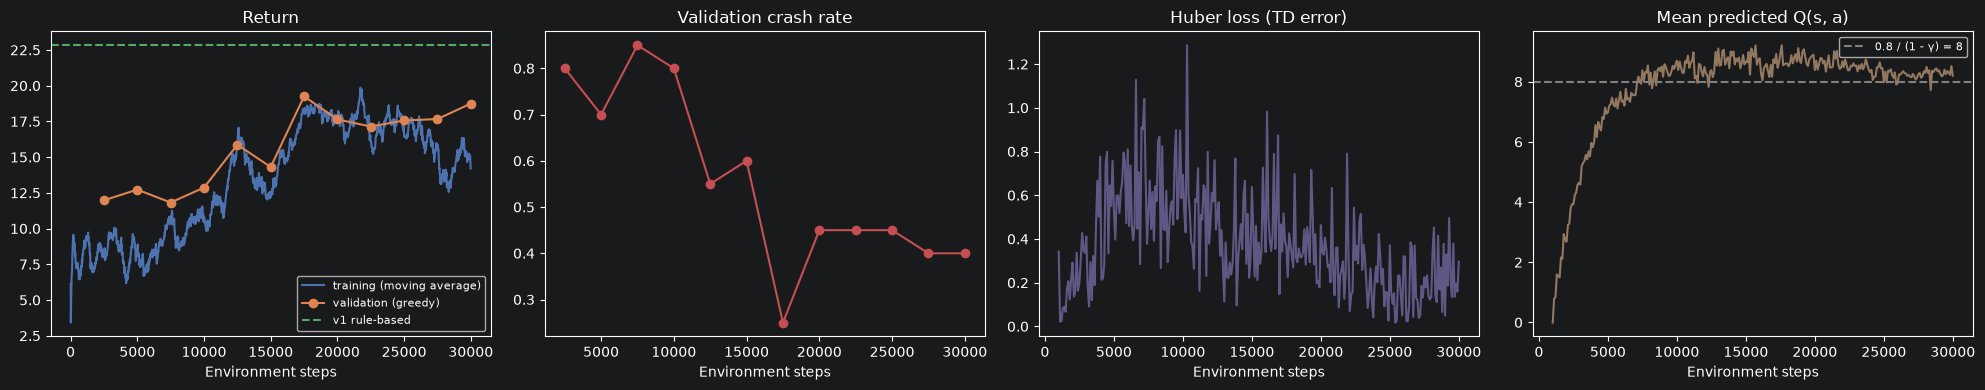

In [7]:
# --- LEARNING CURVES ---

# Moving average over a window.
def moving_average(x, window=50):
    """Average of the last `window` values at every point (shorter at the start)."""

    # As floats.
    x = np.asarray(x, dtype=float)

    # Cumulative sum with a leading zero.
    c = np.concatenate([[0.0], np.cumsum(x)])

    # Start index of each window.
    starts = np.maximum(0, np.arange(1, len(x) + 1) - window)

    # Window sums divided by window lengths.
    return (c[1:] - c[starts]) / (np.arange(1, len(x) + 1) - starts)


# Four panels.
fig, axes = plt.subplots(1, 4, figsize=(20, 4))

# Training return.
axes[0].plot(history["episode_step"], moving_average(history["episode_return"]), color="#4C72B0", label="training (moving average)")

# Validation return.
axes[0].plot(history["val_step"], history["val_return"], marker="o", color="#DD8452", label="validation (greedy)")

# Rule-based reference.
axes[0].axhline(22.83, linestyle="--", color="#55A868", label="v1 rule-based")

# Title.
axes[0].set_title("Return")

# Legend.
axes[0].legend(fontsize=8)

# Validation crash rate.
axes[1].plot(history["val_step"], history["val_crash"], marker="o", color="#C44E52")

# Title.
axes[1].set_title("Validation crash rate")

# Loss.
axes[2].plot(history["loss_step"], history["loss"], color="#8172B3", alpha=0.7)

# Title.
axes[2].set_title("Huber loss (TD error)")

# Mean predicted value.
axes[3].plot(history["loss_step"], history["q"], color="#937860")

# Reference: value of driving safely forever with reward 0.8.
axes[3].axhline(0.8 / (1 - GAMMA), linestyle="--", color="gray", label="0.8 / (1 - γ) = 8")

# Title.
axes[3].set_title("Mean predicted Q(s, a)")

# Legend.
axes[3].legend(fontsize=8)

# Common x label.
for ax in axes:

    # Steps.
    ax.set_xlabel("Environment steps")

# Layout.
plt.tight_layout()

# Render.
plt.show()

## Step 5 — The DQN driver on the 50 test scenarios

The best network on validation, evaluated once on the same 50 test scenarios as all previous drivers.

DQN              return 20.55 | crash rate 18.0% | speed 21.90 m/s | distance  578.5 m | length 26.88
v1 random        return  8.37 | crash rate 96.0% | speed 23.46 m/s | distance  266.2 m | length 11.34
v1 rule-based    return 22.83 | crash rate  2.0% | speed 22.55 m/s | distance  670.4 m | length 29.66
v2 Q-learning    return 23.05 | crash rate  8.0% | speed 23.05 m/s | distance  673.7 m | length 29.24
DQN driver, scenario 1000: return 14.12, CRASH  (videos/v3_dqn.gif)


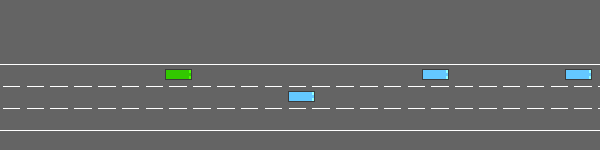

In [8]:
# --- TEST EVALUATION ---

# Evaluate the greedy DQN policy.
res_dqn = evaluate(dqn_policy, env=env_eval)

# Report.
summary("DQN", res_dqn)

# Results of the previous versions.
RESULTS_PATH = RESULTS_DIR / "autopilot_results.json"

# Load them.
results_all = json.loads(RESULTS_PATH.read_text())

# Compare.
for name in ["v1 random", "v1 rule-based", "v2 Q-learning"]:

    # Saved means.
    r = results_all[name]

    # Same format as summary().
    print(f"{name:<16} return {r['return']:5.2f} | crash rate {r['crash']:5.1%} | speed {r['speed']:5.2f} m/s | "
          f"distance {r['distance']:6.1f} m | length {r['length']:5.2f}")

# The DQN driver on the usual scenario.
show_episode(dqn_policy, seed=1000, filename="v3_dqn.gif", title="DQN driver, scenario 1000", env=env_render)

## Step 6 — Inside the agent: its Q-values during an episode

For one test scenario we plot, at every decision, the value the network gives to each of the 5 actions, and mark the action it chose (the highest). This is what the agent "thinks":
- when the road is free, the values are close to each other and high (all actions are fine);
- when a car gets close, the values of the dangerous actions (for example `FASTER`, or `IDLE` behind a slow car) **drop**, and a lane change or `SLOWER` takes over.

### Does it overestimate?
For every test episode we also compare the value the network predicted at the start, $Q_\theta(s_0, a_0)$, with the discounted return the agent then actually obtained, $G_0 = \sum_t \gamma^t r_{t+1}$. Points above the diagonal are overestimates.

Standard DQN is known to **overestimate**: the $\max$ in the target picks the action whose value is most over-estimated by noise, and the error propagates through the targets. (For episodes that reach the 30 s limit, $G_0$ misses the reward after the limit, worth about $\gamma^{30} \cdot 8 \approx 0.3$: a small effect.) Double DQN, in v4, is the fix.

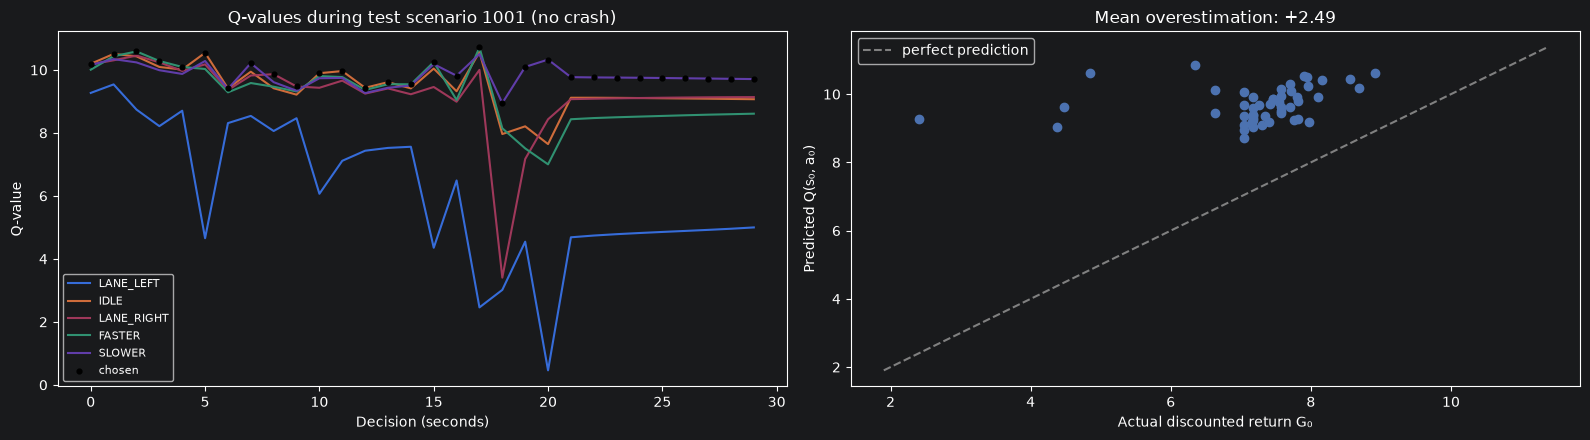

{
  "return": 20.550651835483006,
  "crash": 0.18,
  "speed": 21.898307439674873,
  "distance": 578.4931162817659,
  "length": 26.88
}


In [9]:
# --- Q-VALUES DURING AN EPISODE ---

# Values of all actions for one observation.
@torch.no_grad()
def q_values(obs):
    """Return a NumPy array of 5 Q-values."""

    # Batch of one.
    return q_net(torch.as_tensor(obs, dtype=torch.float32, device=device).unsqueeze(0))[0].cpu().numpy()


# Play one test scenario greedily and record the Q-values.
obs, _ = env_eval.reset(seed=1001)

# Q-values at every decision.
trace = []

# Until the end.
done = False

# Play.
while not done:

    # Values of all actions.
    qs = q_values(obs)

    # Keep them.
    trace.append(qs)

    # Greedy step.
    obs, _, terminated, truncated, info = env_eval.step(int(np.argmax(qs)))

    # End?
    done = terminated or truncated

# As an array (steps x actions).
trace = np.array(trace)

# Two panels.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 4.5))

# One line per action.
for i, name in enumerate(ACTIONS):

    # Its value over time.
    ax1.plot(trace[:, i], label=name)

# Mark the chosen action at each step.
ax1.scatter(range(len(trace)), trace.max(axis=1), color="black", s=12, zorder=3, label="chosen")

# Labels.
ax1.set_xlabel("Decision (seconds)")

# y-axis label.
ax1.set_ylabel("Q-value")

# Title.
ax1.set_title(f"Q-values during test scenario 1001 ({'crash' if info['crashed'] else 'no crash'})")

# Legend.
ax1.legend(fontsize=8)

# --- PREDICTED VALUE vs ACTUAL DISCOUNTED RETURN ---

# Predicted values and actual discounted returns.
predicted, actual = [], []

# Every test scenario.
for seed in EVAL_SEEDS:

    # Start.
    obs, _ = env_eval.reset(seed=seed)

    # Value predicted for the action taken first.
    predicted.append(q_values(obs).max())

    # Discounted return, and the current discount.
    g, discount = 0.0, 1.0

    # Until the end.
    done = False

    # Play greedily.
    while not done:

        # Step.
        obs, r, terminated, truncated, _ = env_eval.step(greedy_action(q_net, obs))

        # Add the discounted reward.
        g += discount * r

        # Next discount.
        discount *= GAMMA

        # End?
        done = terminated or truncated

    # Store the actual return.
    actual.append(g)

# Scatter.
ax2.scatter(actual, predicted, color="#4C72B0")

# Diagonal: perfect prediction.
lims = [min(actual + predicted) - 0.5, max(actual + predicted) + 0.5]

# Draw it.
ax2.plot(lims, lims, linestyle="--", color="gray", label="perfect prediction")

# Labels.
ax2.set_xlabel("Actual discounted return G₀")

# y-axis label.
ax2.set_ylabel("Predicted Q(s₀, a₀)")

# Title.
ax2.set_title(f"Mean overestimation: {np.mean(np.array(predicted) - np.array(actual)):+.2f}")

# Legend.
ax2.legend()

# Layout.
plt.tight_layout()

# Render.
plt.show()

# --- SAVE THE RESULTS ---

# Means of the DQN driver.
results_all["v3 DQN"] = {metric: float(values.mean()) for metric, values in res_dqn.items()}

# Write the file.
RESULTS_PATH.write_text(json.dumps(results_all, indent=2))

# Show the v3 entry.
print(json.dumps(results_all["v3 DQN"], indent=2))

## Results and conclusions

### Summary on the 50 test scenarios
| Driver | Return | Crash rate | Mean speed | Distance | Seconds survived |
|---|---|---|---|---|---|
| v1 random | ~8.5 | ~97% | ~23.5 m/s | ~270 m | ~11 |
| v1 rule-based | 22.83 | **2%** | 22.5 m/s | 670 m | 29.7 |
| v2 Q-learning | **23.05** | 8% | **23.0 m/s** | **674 m** | 29.2 |
| **v3 DQN** | 20.55 | 18% | 21.9 m/s | 578 m | 26.9 |

**The DQN driver is worse than the Q-table**: lower return, more than twice the crashes, lower speed. A neural network is not automatically better than a table: in this run it was less stable and saw less experience.

### Training
- 30,000 steps in about 9.5 minutes (16 ms per step).
- **Up to about 10,000 steps** the greedy policy stays poor (validation return about 12, crash rate 70–85%), while $\varepsilon$ is still high.
- **Best validation return 19.25 at 17,500 steps** (crash rate 25%). After that the validation return stays around 17–19, with 40–45% crashes, and the training return even **drops** (from about 18 to 14): more training did not mean a better driver.
- The **loss** stays between about 0.1 and 0.6 with no explosion, but as expected it says little about the quality of the driver.

### Overestimation, measured
- The mean predicted $Q(s, a)$ on the training batches rises above the reference value of 8 and stays at 8.5–9.
- On the test scenarios, the value predicted at the start of an episode is about **2.5 higher than the discounted return actually obtained** (predicted about 9–10.5, actual about 7–8). Almost all the points are above the diagonal.
- This is the classic **overestimation bias** of DQN: the $\max$ in the target always picks the action whose value is most over-estimated by noise, and the error feeds back into the next targets.

### Inside the agent
In test scenario 1001 (no crash) the values of most actions are close to each other while the road is free. Around second 18 the values of `LANE_RIGHT`, `IDLE` and `FASTER` **drop sharply** and the agent chooses `SLOWER`: it sees a danger and brakes. After that it keeps choosing `SLOWER` until the end, which explains its low average speed: once it has slowed down, it does not try to speed up again.

### Why did the network do worse than the table?
- **Less experience:** 30,000 steps are about 1,250 episodes, against 2,000 episodes (about 45,000 steps) for Q-learning.
- **A harder input:** the Q-table received ready-made features ("gap ahead in the left lane", "car beside on the right"), hand-picked for this problem. The network receives 10 raw rows sorted by distance, and must discover by itself which row is which car and which lane matters. The row of "the car ahead in my lane" can be any of the 10.
- **Instability and overestimation:** the targets move as the network changes, and they are inflated by the $\max$.
- **Noisy model selection:** 20 validation episodes are few; with one crash worth 5 percentage points, the "best" network is partly chosen by luck.

### Next step
**v4: better DQN.** Three changes, each aimed at one of the problems above:
- **Double DQN** against the overestimation measured here;
- **Dueling** architecture: it learns the value of a situation separately from the advantage of each action, useful because in many situations all actions are worth about the same;
- **attention over vehicles** instead of a flat MLP: each car is processed by the same small network, and the agent learns **which cars to look at**. It is the same idea as the attention of ChessGPT v4, applied to traffic, and we will be able to visualise it.